# Credit Risk — model, calibration, and underwriting policy validation

**Decision question.** Does the challenger preserve ranking out of time, can probability drift be repaired on later data, and what approval policy remains economically transparent?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: credit-risk-decision-lab


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['reports/model_metrics.csv', 'reports/binned_baseline_metrics.csv', 'reports/oot_policy_validation.csv', 'reports/policy_sensitivity.csv', 'reports/recalibration_backtest.csv', 'reports/reason_code_summary.csv', 'reports/run_metadata.json', 'reports/figures/oot_model_comparison.png', 'reports/figures/oot_policy_frontier.png', 'reports/figures/recalibration_and_reasons.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,reports/model_metrics.csv,True,1774
1,reports/binned_baseline_metrics.csv,True,1002
2,reports/oot_policy_validation.csv,True,1969
3,reports/policy_sensitivity.csv,True,2274
4,reports/recalibration_backtest.csv,True,866
5,reports/reason_code_summary.csv,True,6541
6,reports/run_metadata.json,True,6933
7,reports/figures/oot_model_comparison.png,True,59170
8,reports/figures/oot_policy_frontier.png,True,71083
9,reports/figures/recalibration_and_reasons.png,True,87627


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `reports/model_metrics.csv`

In [4]:
frame_1 = load_artifact('reports/model_metrics.csv')
audit_frame(frame_1, 'reports/model_metrics.csv')

#### Data-quality audit — `reports/model_metrics.csv`

,metric,value
0,rows,6
1,columns,16
2,missing cells,0
3,duplicate rows,0
4,numeric columns,14


,model,partition,rows,roc_auc,gini,average_precision,brier_score,ece_10,observed_default_rate,mean_predicted_pd,stability_score,stability_mean_gini,stability_slope,stability_falling_rate,stability_residual_std,stability_eligible_weeks
0,linear,calibration,171375,0.6846,0.3693,0.1027,0.0421,0.0068,0.0451,0.0451,-0.5539,0.3517,-0.0101,-0.0101,0.0358,14
1,challenger,calibration,171375,0.7923,0.5847,0.1789,0.0400,0.0023,0.0451,0.0452,0.4428,0.5816,-0.0013,-0.0013,0.0477,14
2,linear,policy,73807,0.7011,0.4021,0.0700,0.0228,0.0178,0.0235,0.0413,0.3428,0.3794,0.0211,0.0000,0.0733,9
3,challenger,policy,73807,0.8065,0.6130,0.1273,0.0220,0.0123,0.0235,0.0358,0.5766,0.6039,0.0001,0.0000,0.0547,9
4,linear,oot,151707,0.7113,0.4227,0.0644,0.0208,0.0201,0.0212,0.0413,0.3943,0.4183,0.0014,0.0000,0.0479,14
5,challenger,oot,151707,0.8253,0.6507,0.1384,0.0197,0.0129,0.0212,0.0341,0.6164,0.6398,0.0035,0.0000,0.0468,14


,count,mean,std,min,50%,max
rows,6.0000,"132,296.3333","46,151.5689","73,807.0000","151,707.0000","171,375.0000"
roc_auc,6.0000,0.7535,0.0612,0.6846,0.7518,0.8253
gini,6.0000,0.5071,0.1225,0.3693,0.5037,0.6507
average_precision,6.0000,0.1137,0.0436,0.0644,0.1150,0.1789
brier_score,6.0000,0.0279,0.0102,0.0197,0.0224,0.0421
ece_10,6.0000,0.0120,0.0067,0.0023,0.0126,0.0201
observed_default_rate,6.0000,0.0299,0.0118,0.0212,0.0235,0.0451
mean_predicted_pd,6.0000,0.0405,0.0046,0.0341,0.0413,0.0452
stability_score,6.0000,0.3032,0.4329,-0.5539,0.4186,0.6164
stability_mean_gini,6.0000,0.4958,0.1266,0.3517,0.4999,0.6398


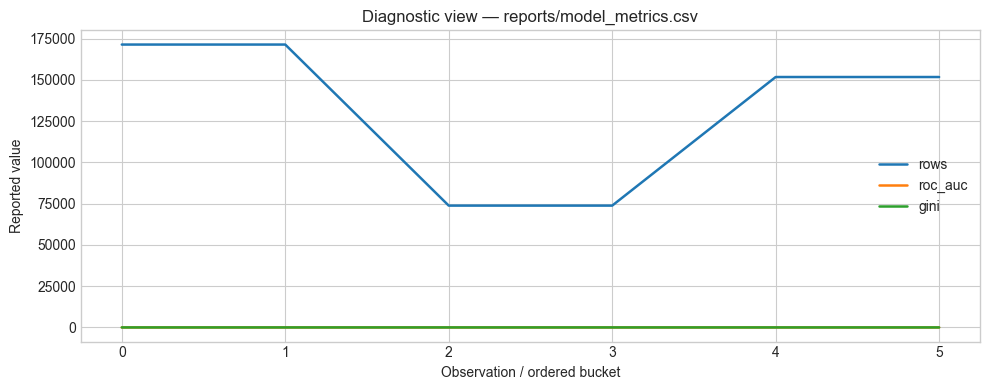

In [5]:
plot_numeric(frame_1, 'Diagnostic view — reports/model_metrics.csv')

## 3. Evidence table — `reports/binned_baseline_metrics.csv`

In [6]:
frame_2 = load_artifact('reports/binned_baseline_metrics.csv')
audit_frame(frame_2, 'reports/binned_baseline_metrics.csv')

#### Data-quality audit — `reports/binned_baseline_metrics.csv`

,metric,value
0,rows,3
1,columns,16
2,missing cells,0
3,duplicate rows,0
4,numeric columns,14


,model,partition,rows,roc_auc,gini,average_precision,brier_score,ece_10,observed_default_rate,mean_predicted_pd,stability_score,stability_mean_gini,stability_slope,stability_falling_rate,stability_residual_std,stability_eligible_weeks
0,binned_logistic,calibration,171375,0.7483,0.4966,0.1359,0.0412,0.0032,0.0451,0.0451,0.4688,0.4991,0.0011,0.0000,0.0607,14
1,binned_logistic,policy,73807,0.7815,0.5631,0.0983,0.0221,0.0073,0.0235,0.0308,0.5103,0.5459,0.0058,0.0000,0.0712,9
2,binned_logistic,oot,151707,0.7870,0.5739,0.0964,0.0201,0.0096,0.0212,0.0308,0.5446,0.5646,0.0038,0.0000,0.0399,14


,count,mean,std,min,50%,max
rows,3.0000,"132,296.3333","51,599.0227","73,807.0000","151,707.0000","171,375.0000"
roc_auc,3.0000,0.7723,0.0209,0.7483,0.7815,0.7870
gini,3.0000,0.5445,0.0419,0.4966,0.5631,0.5739
average_precision,3.0000,0.1102,0.0223,0.0964,0.0983,0.1359
brier_score,3.0000,0.0278,0.0116,0.0201,0.0221,0.0412
ece_10,3.0000,0.0067,0.0032,0.0032,0.0073,0.0096
observed_default_rate,3.0000,0.0299,0.0132,0.0212,0.0235,0.0451
mean_predicted_pd,3.0000,0.0356,0.0083,0.0308,0.0308,0.0451
stability_score,3.0000,0.5079,0.0380,0.4688,0.5103,0.5446
stability_mean_gini,3.0000,0.5365,0.0337,0.4991,0.5459,0.5646


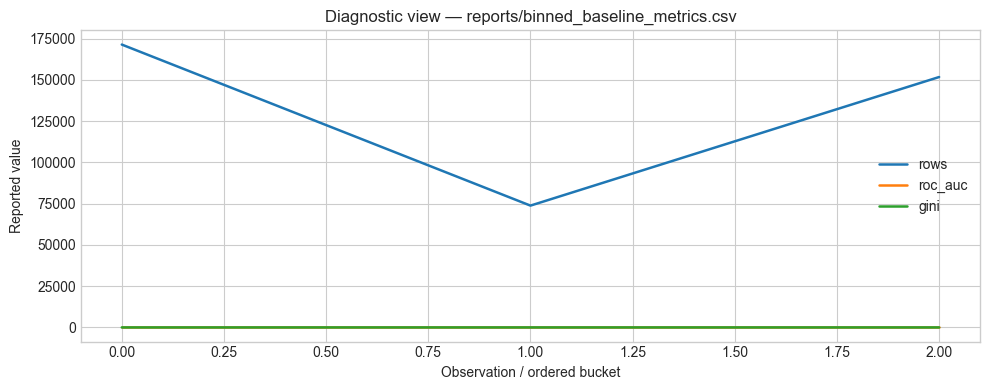

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/binned_baseline_metrics.csv')

## 4. Evidence table — `reports/oot_policy_validation.csv`

In [8]:
frame_3 = load_artifact('reports/oot_policy_validation.csv')
audit_frame(frame_3, 'reports/oot_policy_validation.csv')

#### Data-quality audit — `reports/oot_policy_validation.csv`

,metric,value
0,rows,12
1,columns,10
2,missing cells,0
3,duplicate rows,0
4,numeric columns,10


,target_policy_approval_rate,frozen_pd_cutoff,oot_approval_rate,oot_approved_count,oot_observed_bad_rate,oot_mean_predicted_pd,oot_approved_exposure,oot_expected_loss_scenario,oot_realised_loss_proxy,lgd_assumption
0,0.2000,0.0075,0.2094,31760,0.0015,0.0043,"1,477,357,904.6229","1,652,962.8013","504,670.7018",0.2500
1,0.2000,0.0075,0.2094,31760,0.0015,0.0043,"1,477,357,904.6229","2,975,333.0424","908,407.2632",0.4500
2,0.2000,0.0075,0.2094,31760,0.0015,0.0043,"1,477,357,904.6229","4,297,703.2834","1,312,143.8246",0.6500
3,0.4000,0.0157,0.4233,64222,0.0032,0.0079,"3,355,128,678.7421","7,057,995.6137","3,072,209.7027",0.2500
4,0.4000,0.0157,0.4233,64222,0.0032,0.0079,"3,355,128,678.7421","12,704,392.1047","5,529,977.4649",0.4500
5,0.4000,0.0157,0.4233,64222,0.0032,0.0079,"3,355,128,678.7421","18,350,788.5957","7,987,745.2271",0.6500
6,0.6000,0.0257,0.6198,94027,0.0053,0.0119,"4,997,796,350.8944","15,398,705.2557","7,438,772.2057",0.2500
7,0.6000,0.0257,0.6198,94027,0.0053,0.0119,"4,997,796,350.8944","27,717,669.4602","13,389,789.9703",0.4500


,count,mean,std,min,50%,max
target_policy_approval_rate,12.0000,0.5000,0.2335,0.2000,0.5000,0.8000
frozen_pd_cutoff,12.0000,0.0243,0.0159,0.0075,0.0207,0.0482
oot_approval_rate,12.0000,0.5150,0.2326,0.2094,0.5216,0.8075
oot_approved_count,12.0000,"78,126.5000","35,283.6092","31,760.0000","79,124.5000","122,497.0000"
oot_observed_bad_rate,12.0000,0.0048,0.0030,0.0015,0.0043,0.0092
oot_mean_predicted_pd,12.0000,0.0103,0.0050,0.0043,0.0099,0.0172
oot_approved_exposure,12.0000,"4,144,655,066.0751","2,039,039,710.3008","1,477,357,904.6229","4,176,462,514.8182","6,748,337,330.0409"
oot_expected_loss_scenario,12.0000,"24,653,157.6253","23,824,370.5883","1,652,962.8013","16,874,746.9257","79,755,340.7358"
oot_realised_loss_proxy,12.0000,"12,989,289.2941","14,126,954.7117","504,670.7018","7,713,258.7165","46,408,530.2460"
lgd_assumption,12.0000,0.4500,0.1706,0.2500,0.4500,0.6500


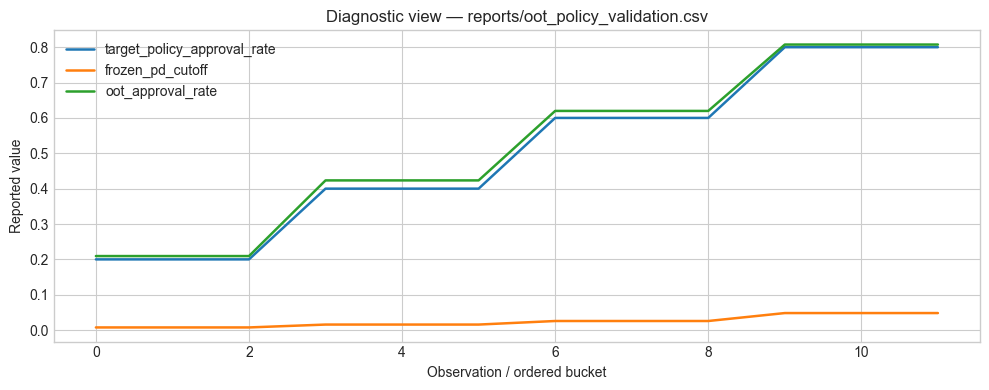

In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/oot_policy_validation.csv')

## 5. Evidence table — `reports/policy_sensitivity.csv`

In [10]:
frame_4 = load_artifact('reports/policy_sensitivity.csv')
audit_frame(frame_4, 'reports/policy_sensitivity.csv')

#### Data-quality audit — `reports/policy_sensitivity.csv`

,metric,value
0,rows,12
1,columns,11
2,missing cells,0
3,duplicate rows,0
4,numeric columns,10


,selection_partition,approval_rate,pd_cutoff,approved_count,observed_bad_rate,mean_predicted_pd,approved_exposure,expected_loss_scenario,realised_loss_proxy,lgd_assumption,oot_score_psi
0,policy,0.2000,0.0075,14761,0.0020,0.0044,"645,794,489.2167","733,925.2163","357,829.3505",0.2500,0.0028
1,policy,0.4000,0.0157,29522,0.0042,0.0080,"1,444,154,357.5269","3,044,261.7347","1,943,691.6040",0.2500,0.0028
2,policy,0.6000,0.0257,44284,0.0068,0.0121,"2,199,538,346.9195","6,885,848.3941","4,129,819.9065",0.2500,0.0028
3,policy,0.8000,0.0482,59045,0.0107,0.0177,"3,038,842,431.4540","14,231,582.9720","8,944,120.7102",0.2500,0.0028
4,policy,0.2000,0.0075,14761,0.0020,0.0044,"645,794,489.2167","1,321,065.3894","644,092.8309",0.4500,0.0028
5,policy,0.4000,0.0157,29522,0.0042,0.0080,"1,444,154,357.5269","5,479,671.1225","3,498,644.8872",0.4500,0.0028
6,policy,0.6000,0.0257,44284,0.0068,0.0121,"2,199,538,346.9195","12,394,527.1093","7,433,675.8317",0.4500,0.0028
7,policy,0.8000,0.0482,59045,0.0107,0.0177,"3,038,842,431.4540","25,616,849.3496","16,099,417.2784",0.4500,0.0028


,count,mean,std,min,50%,max
approval_rate,12.0000,0.5000,0.2335,0.2000,0.5000,0.8000
pd_cutoff,12.0000,0.0243,0.0159,0.0075,0.0207,0.0482
approved_count,12.0000,"36,903.0000","17,237.6015","14,761.0000","36,903.0000","59,045.0000"
observed_bad_rate,12.0000,0.0059,0.0034,0.0020,0.0055,0.0107
mean_predicted_pd,12.0000,0.0105,0.0052,0.0044,0.0100,0.0177
approved_exposure,12.0000,"1,832,082,406.2793","926,733,386.1741","645,794,489.2167","1,821,846,352.2232","3,038,842,431.4540"
expected_loss_scenario,12.0000,"11,203,028.2427","11,083,383.6043","733,925.2163","7,400,464.4521","37,002,115.7271"
realised_loss_proxy,12.0000,"6,918,957.7071","6,981,025.2175","357,829.3505","4,591,709.0384","23,254,713.8467"
lgd_assumption,12.0000,0.4500,0.1706,0.2500,0.4500,0.6500
oot_score_psi,12.0000,0.0028,0.0000,0.0028,0.0028,0.0028


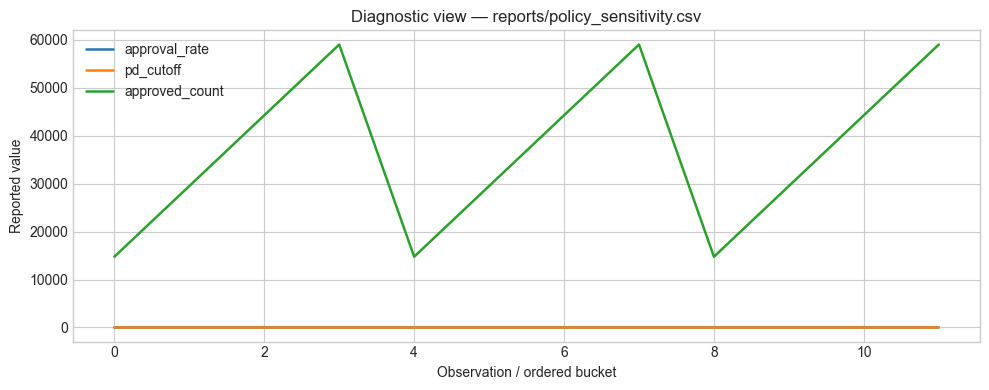

In [11]:
plot_numeric(frame_4, 'Diagnostic view — reports/policy_sensitivity.csv')

## 6. Evidence table — `reports/recalibration_backtest.csv`

In [12]:
frame_5 = load_artifact('reports/recalibration_backtest.csv')
audit_frame(frame_5, 'reports/recalibration_backtest.csv')

#### Data-quality audit — `reports/recalibration_backtest.csv`

,metric,value
0,rows,2
1,columns,18
2,missing cells,0
3,duplicate rows,0
4,numeric columns,15


,version,fit_weeks,evaluation_weeks,rows,logit_intercept_offset,roc_auc,gini,average_precision,brier_score,ece_10,observed_default_rate,mean_predicted_pd,stability_score,stability_mean_gini,stability_slope,stability_falling_rate,stability_residual_std,stability_eligible_weeks
0,original_calibration,55-68,85-91,102366,0.0000,0.8335,0.6670,0.1467,0.0191,0.0135,0.0206,0.0341,0.0889,0.6665,-0.0064,-0.0064,0.0292,7
1,intercept_refresh,78-84,85-91,102366,-0.4250,0.8335,0.6670,0.1467,0.0188,0.0027,0.0206,0.0231,0.0889,0.6665,-0.0064,-0.0064,0.0292,7


,count,mean,std,min,50%,max
rows,2.0000,"102,366.0000",0.0000,"102,366.0000","102,366.0000","102,366.0000"
logit_intercept_offset,2.0000,-0.2125,0.3005,-0.4250,-0.2125,0.0000
roc_auc,2.0000,0.8335,0.0000,0.8335,0.8335,0.8335
gini,2.0000,0.6670,0.0000,0.6670,0.6670,0.6670
average_precision,2.0000,0.1467,0.0000,0.1467,0.1467,0.1467
brier_score,2.0000,0.0189,0.0002,0.0188,0.0189,0.0191
ece_10,2.0000,0.0081,0.0077,0.0027,0.0081,0.0135
observed_default_rate,2.0000,0.0206,0.0000,0.0206,0.0206,0.0206
mean_predicted_pd,2.0000,0.0286,0.0078,0.0231,0.0286,0.0341
stability_score,2.0000,0.0889,0.0000,0.0889,0.0889,0.0889


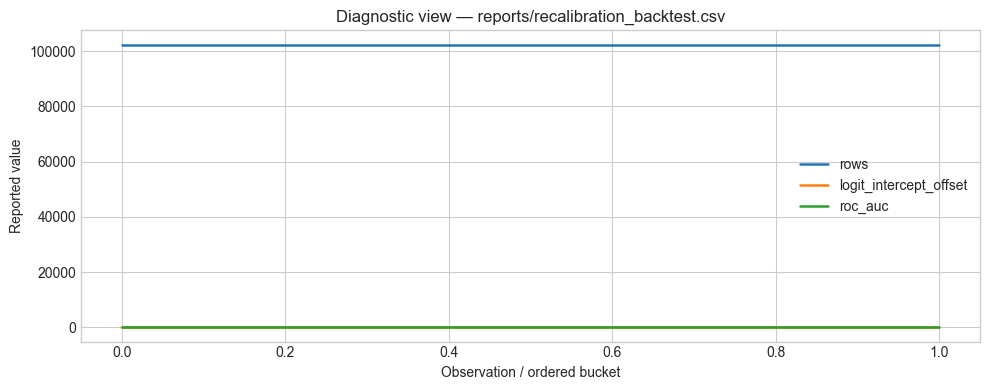

In [13]:
plot_numeric(frame_5, 'Diagnostic view — reports/recalibration_backtest.csv')

## 7. Evidence table — `reports/reason_code_summary.csv`

In [14]:
frame_6 = load_artifact('reports/reason_code_summary.csv')
audit_frame(frame_6, 'reports/reason_code_summary.csv')

#### Data-quality audit — `reports/reason_code_summary.csv`

,metric,value
0,rows,61
1,columns,5
2,missing cells,0
3,duplicate rows,0
4,numeric columns,3


,feature,description,applications_as_top_reason,share_as_top_reason,mean_positive_log_odds_contribution
0,annuity_780A,Monthly annuity amount.,2291,0.2291,0.3074
1,avgdpdtolclosure24_3658938P,Average DPD (days past due) with tolerance wit...,1286,0.1286,0.4929
2,lastrejectdate_50D,Date of most recent rejected application by th...,958,0.0958,0.2777
3,mobilephncnt_593L,Number of persons with the same mobile phone n...,949,0.0949,0.3369
4,pmtnum_254L,Total number of loan payments made by the client.,917,0.0917,0.2641
5,thirdquarter_1082L,Number of results in third quarter.,432,0.0432,0.1428
6,eir_270L,Interest rate.,363,0.0363,0.2156
7,maxinstallast24m_3658928A,Maximum instalment in the last 24 months,304,0.0304,0.3050


,count,mean,std,min,50%,max
applications_as_top_reason,61.0000,163.9344,381.0156,1.0000,17.0000,"2,291.0000"
share_as_top_reason,61.0000,0.0164,0.0381,0.0001,0.0017,0.2291
mean_positive_log_odds_contribution,61.0000,0.1675,0.1064,0.0530,0.1332,0.6100


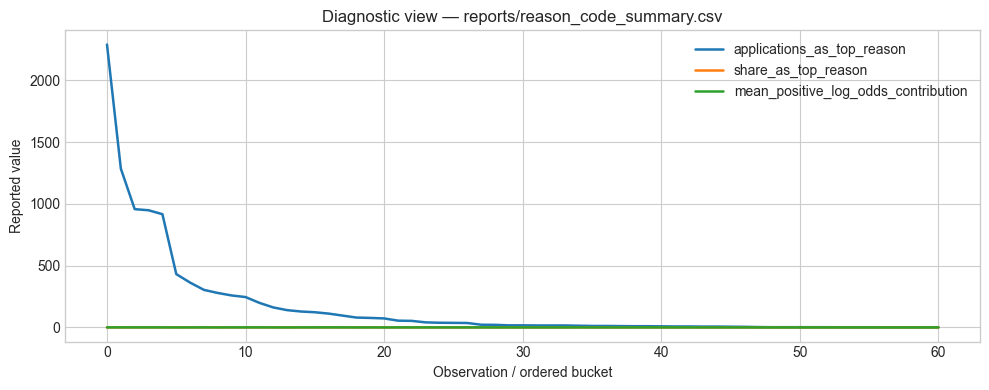

In [15]:
plot_numeric(frame_6, 'Diagnostic view — reports/reason_code_summary.csv')

## 8. Locked decision object — `reports/run_metadata.json`

In [16]:
payload = load_artifact('reports/run_metadata.json')
show_json(payload, 'reports/run_metadata.json')

#### reports/run_metadata.json

,field,value
0,seed,20261004
1,fit_rows,600000
2,fit_weeks,"[0, 47]"
3,tune_weeks,"[48, 54]"
4,best_iteration,1194
5,feature_manifest,"{""numeric"": [""actualdpdtolerance_344P"", ""amtin..."
6,categorical_feature_count,19
7,exposure_proxy,credamount_770A
8,claim_boundary,Source target is not represented as regulatory...


## Visual evidence

![oot_model_comparison](../reports/figures/oot_model_comparison.png)

![oot_policy_frontier](../reports/figures/oot_policy_frontier.png)

![recalibration_and_reasons](../reports/figures/recalibration_and_reasons.png)

## Decision

**Advance to shadow mode, not automated decline. Preserve ranking evidence, recalibrate absolute PD on strictly later data, and keep approval/manual-review cutoffs governed by capacity and loss assumptions.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [17]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

Economic outputs are scenario analyses rather than realised lender P&L. Aggregate reason codes are not individual adverse-action notices or a fairness audit.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.